## AI usage statement

*Fill this in before you submit the notebook — it is part of your submission.*

**Did you use AI tools (e.g. ChatGPT, Claude, Copilot, Gemini) for this notebook?** Replace `[ ]` by `[x]`:

- [ ] No, I did not use any AI tools.
- [ ] Yes, as described in the table below.

| Tool (name/version) | What I used it for (e.g. explaining a concept, writing or debugging code, phrasing an answer) | Tasks / cells | How I checked the result |
|---|---|---|---|
| | | | |

**I confirm** that I understand every piece of code and every answer in this notebook and can explain them myself.

Name: … &nbsp;&nbsp; Date: …

# Polymer Data and Fingerprints

Machine learning starts with the data. In this notebook you work with a DFT dataset of **polymer band gaps** and
turn polymers into **fingerprints** — fixed-length vectors that a standard machine-learning model can use.

| Section | You learn |
|---|---|
| 1 | Loading the dataset; polymer SMILES (PSMILES); looking at the data |
| 2 | Data quality: unknown elements, questionable entries, duplicates |
| 3 | Morgan (circular) fingerprints and molecular similarity |
| 4 | A reproducible train / validation / test split |
| 5 | A first model: random forest on fingerprints; choosing hyper-parameters on the validation set |
| 6 | Fingerprints for other material classes: multi-component (MOFs) and atomistic (3D crystals) |

The **GNN notebook** starts from exactly the cleaned dataset and the split you build here, so you can compare
fingerprints with graph neural networks on the same test set.

> **Runtime:** about 2 minutes on a laptop CPU.

---
## Setup

In [ ]:
import random
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from psmiles import PolymerSmiles
from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import Draw, rdFingerprintGenerator
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

RDLogger.DisableLog("rdApp.*")  # suppress RDKit warnings

---
## Section 1: Loading the Data


The dataset is a DFT-level computational dataset of polymer electronic properties. Each row represents one polymer **repeat unit**
encoded as a SMILES string with `[*]` attachment-point wildcards.

The CSV has three columns:

| Column | Description |
|---|---|
| `smiles` | Repeat-unit PSMILES; `[*]` shows chain attachment points |
| `property` |  `Egc` (computed band gap) and others (ignore other properties) |
| `value` | Numerical value of the property |


---
### Notes on PSMILES

Standard SMILES strings encode molecules. Polymer repeat units (monomers) instead use attachment-point wildcards `[*]` (atomic number 0, symbol `*`) to mark where one repeat unit connects to the next:

```
[*]CC([*])C    ←  polypropylene monomer unit
 ↑     ↑
 polymer chain connection points
```

These star atoms are retained in the graph because they encode structural information about chain connectivity.


## Todo:
1. Load dataset from `https://raw.githubusercontent.com/kuennethgroup/materials_datasets/refs/heads/main/polymer_band_gap_computational/export.csv` using `pandas`
2. Exclude all properties except `property == 'Egc'` 
3. Count values, compute mean and standard deviation of the target property `Egc`
4. Plot the distribution of `Egc` values (e.g. histogram or KDE plot)


Shows the expected output, which you can use to verify

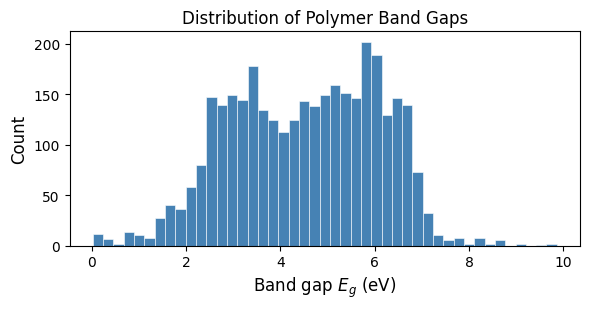

### 1.3 Look at the polymers first

Before training any model, look at the data. A good model should learn chemistry that you can
already see by eye.

**Task:** Draw the 6 polymers with the **lowest** and the 6 with the **highest** band gap using
`rdkit.Chem.Draw.MolsToGridImage` (`legends=` lets you print the band gap under each structure).

In [ ]:
from rdkit.Chem import Draw

# TODO: select the 6 lowest and 6 highest band-gap rows (hint: df.nsmallest / df.nlargest)
# and draw them with Draw.MolsToGridImage(mols, molsPerRow=6, legends=[...]).
# Use display(...) to show more than one image in a single cell.

**Questions:**
1. What do the **high-gap** polymers have in common? *(Saturated backbones? Fluorine?)*
2. Look closely at the **low-gap** structures. Some are conjugated (aromatic rings, double bonds, thiophenes) —
   as expected. But several contain a positively charged nitrogen (`[N+]`) and are otherwise saturated.
   Count the charged entries in the dataset (hint: `atom.GetFormalCharge()`) and compare their band gaps with
   the rest. Do you trust these labels? What is physically missing from a charged repeat unit?
3. What would you do with such entries before training a model — and what would you have to report if you did?

*Looking at extreme values is one of the most effective ways to find data problems.*

---
## Section 2: Data Quality

### 2.1 Which elements occur?

The GNN notebook encodes every atom with a one-hot vector over the elements
`C, N, O, F, P, S, Cl, Br, Si, *`. An atom with any other symbol would get an **all-zero** encoding — silently.

**Task 2.1:** Count how often every element occurs in the dataset and print the ones that are **not** in
`ATOM_SYMBOLS`.

In [ ]:
ATOM_SYMBOLS = ["C", "N", "O", "F", "P", "S", "Cl", "Br", "Si", "*"]

# TODO: use collections.Counter over atom.GetSymbol() for all atoms of all molecules,
# then print the elements that are not in ATOM_SYMBOLS (and how often they occur).

### 2.2 Entries with a net charge

**Task 2.2:** Compute the net formal charge of every repeat unit (`atom.GetFormalCharge()`), show the charged
entries with their band gaps, and **remove them** from `df` (see the questions in Section 1.3). Print how many
entries remain. Removing data is a curation decision — always print and report what you removed.

In [ ]:
# TODO: net charge of every repeat unit (sum of atom.GetFormalCharge() over all atoms)
# TODO: show the charged entries (smiles, value) and compare their mean band gap with the neutral ones
# TODO: df = only the neutral entries (use .reset_index(drop=True)); print the number of remaining entries

### 2.3 Duplicates — the same polymer written twice

The same polymer can be written in many ways: `[*]C[*]`, `[*]CC[*]`, and `[*]CCCC[*]` are all polyethylene, and
atoms can be listed in any order. The group's [`psmiles`](https://github.com/kuennethgroup/psmiles) package
computes a **canonical** form: `PolymerSmiles("[*]CCCC[*]").canonicalize` → `[*]C[*]`.

**Task 2.3:** Add a column `canonical` with the canonical PSMILES of every entry (≈ 10 s), print the number of
unique SMILES and of unique *polymers*, and show all entries whose canonical form occurs more than once.

In [ ]:
# TODO: df["canonical"] = canonical PSMILES of every entry (str(PolymerSmiles(s).canonicalize))
# TODO: number of unique SMILES and unique canonical forms
# TODO: duplicates = all rows whose canonical form occurs more than once (hint: .duplicated(keep=False))

**Questions (Section 2):**
1. What would a one-hot encoding over `ATOM_SYMBOLS` do with the elements you found in Task 2.1?
2. The duplicate polymer has two different band gaps. What does the difference tell you about the uncertainty of
   the labels — and therefore about the smallest error a model can sensibly reach?
3. Why are duplicates dangerous when you split the data into training and test sets? (You will check where the two
   copies end up in Section 4.)

---
## Section 3: Fingerprints

Most machine-learning models need a **fixed-length vector** per sample, but polymers have different numbers of
atoms. A **fingerprint** solves this. The most common one is the **Morgan (circular) fingerprint** (ECFP):

1. Every atom gets an identifier from its element, degree, charge, …
2. For radius $r = 1, 2, \dots$ the identifier is updated with the identifiers of the neighbours — after $r$
   steps it describes the circular substructure of radius $r$ around the atom.
3. Every identifier is **hashed** to a position in a bit vector of length `fpSize`, and that bit is set to 1.

The result says *which substructures occur*, not where. Notice how similar step 2 is to message passing in a GNN —
the difference is that a GNN *learns* the update instead of hashing it.

### 3.1 Morgan fingerprints for all polymers

**Task 3.1:** Use `rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)` and its method
`GetFingerprintAsNumPy(mol)` to build a matrix `X` with one row per polymer. Print its shape, the average number of
bits that are set per polymer, and the fraction of the 2048 bit positions that are used at least once.

In [ ]:
fp_gen = None  # TODO: Morgan fingerprint generator (radius 2, 2048 bits)


def morgan_fp(smiles, generator=fp_gen):
    # TODO: return the fingerprint of `smiles` as a NumPy array
    pass


# TODO: X = one fingerprint per row for all polymers in df; print the statistics described above

### 3.2 Similarity

The **Tanimoto similarity** of two fingerprints is (bits set in both) / (bits set in either); 1 means identical.

**Task 3.2:**
1. Compute the Tanimoto similarity between `[*]C[*]` and `[*]CC[*]` (both polyethylene). Repeat it after
   canonicalising both with `psmiles`.
2. Find the 5 polymers in the dataset that are most similar to polystyrene, `[*]CC([*])c1ccccc1`
   (`DataStructs.BulkTanimotoSimilarity`), and draw them with their band gaps.

In [ ]:
def tanimoto(smiles_a, smiles_b):
    # TODO: Tanimoto similarity of the fingerprints (fp_gen.GetFingerprint(mol), DataStructs.TanimotoSimilarity)
    pass


# TODO 1: [*]C[*] vs [*]CC[*], before and after canonicalisation
# TODO 2: similarity of every polymer in df to polystyrene; the 5 most similar; draw them with their band gaps

**Questions (Section 3):**
1. Why do `[*]C[*]` and `[*]CC[*]` have different fingerprints although they are the same polymer? What would this
   mean for a model trained on fingerprints?
2. Look at the band gaps of polystyrene's nearest neighbours. Which differences are chemically plausible (think of
   conjugation), and which one would you double-check? What does this mean for the idea "similar structure →
   similar property" on which fingerprint models rely?

---
## Section 4: Train / Validation / Test Split

We split the cleaned dataset **70 / 15 / 15 %** into training, validation, and test sets with a fixed random seed.
The GNN notebook uses **exactly the same procedure**, so all models are evaluated on the same test polymers.

**Task 4:**
1. `random.seed(42)`, create the list of indices `0 … n-1` and shuffle it with `random.shuffle`.
2. `n_train = int(0.70 * n)`, `n_val = int(0.15 * n)`; slice the shuffled list into `train_idx`, `val_idx`,
   `test_idx`.
3. Check in which set(s) the two copies of the duplicate polymer from Section 2.3 ended up.

In [ ]:
# TODO 1-2: random.seed(42), shuffled indices, train_idx / val_idx / test_idx (70 / 15 / 15)

# TODO 3: in which set is each row of `duplicates`?

---
## Section 5: A First Model on Fingerprints

**Task 5.1:**
1. As a reference, compute the MAE of the **mean predictor** (always predict the mean training band gap) on the
   test set.
2. Train a `RandomForestRegressor(n_estimators=200, random_state=0, n_jobs=-1)` on `X[train_idx]` and report MAE
   and $R^2$ on the validation and the test set (≈ 10 s).
3. Make a parity plot (predicted vs. DFT band gap) for the test set.

Store every test MAE in the dictionary `results` — you will compare them at the end.

In [ ]:
y = df["value"].to_numpy()
results = {}

# TODO 1: results["mean predictor"] = test MAE of the mean predictor
# TODO 2: random forest; print validation and test MAE / R²; results["Morgan (r=2) + random forest"] = test MAE
# TODO 3: parity plot for the test set

### 5.2 Choosing a hyper-parameter — on the validation set

The fingerprint radius is a **hyper-parameter**. Choosing it by looking at the *test* error would make the test
error optimistic, so we use the **validation** set.

**Task 5.2:** For radius 1, 2, and 3, build the fingerprints, train the same random forest on the training set, and
print the validation MAE (≈ 30 s). Pick the best radius and report its **test** MAE once.

In [ ]:
# TODO: loop over radius 1, 2, 3: fingerprints, random forest on train, validation MAE
# TODO: best radius by validation MAE; report its test MAE in results[...]

**Questions (Section 5):**
1. How much better than the mean predictor is the random forest?
2. Which radius works best? Why could a *smaller* radius work better although it describes less of the molecule?
   *(Think about the number of training polymers, how often each bit is set, and hash collisions.)*
3. In the GNN notebook you will train a graph neural network on the same split. Which model do you expect to win,
   and why?

---
## Section 6: Fingerprints for Other Material Classes

So far every fingerprint in this notebook described a single organic molecule from its SMILES string. The
lecture also covered two other common cases, and both are quick to build:

- **6.1 Multi-component materials** — a material assembled from several distinct building blocks, e.g. a
  metal–organic framework (MOF) made of metal nodes and organic linkers.
- **6.2 Atomistic (3D) structures** — materials with no SMILES at all, e.g. periodic metal crystals, described
  only by atomic positions and a unit cell.

Both parts are short, self-contained demonstrations, independent of the band-gap workflow above.

### 6.1 Multi-component Fingerprints: Metal–Organic Frameworks

A metal–organic framework (MOF) is assembled from two kinds of building blocks: **metal nodes** (e.g. a Zn₄O
cluster) and **organic linkers** (e.g. a dicarboxylic acid) that connect the nodes into a 3D framework. Neither
building block alone describes the material, so a single-molecule fingerprint does not apply directly.

The simplest fix: fingerprint each building block separately with the method you already have (a Morgan
fingerprint), then **concatenate** the two vectors. An optional `ratio` rescales the linker fingerprint, so the
combined vector can also reflect the node : linker stoichiometry of the framework.

**Task 6.1:** Implement `get_mof_fingerprint(metal_mol, linker_mol, ratio, radius, n_bits)`. Test it on a
simplified node of **MOF-5** (`Zn₄O(BDC)₃` — a single Zn atom stands in for the Zn₄O cluster here) and
1,4-benzenedicarboxylic acid (BDC, terephthalic acid) as the linker, with `ratio=3` for the node : linker ratio
of the real framework.

In [ ]:
def get_mof_fingerprint(metal_mol, linker_mol, ratio=1.0, radius=2, n_bits=1024):
    """Concatenate the Morgan fingerprints of a metal node and an organic linker."""
    # TODO: Morgan generator (radius, n_bits); fingerprint of metal_mol and of linker_mol (as NumPy arrays)
    # TODO: return np.concatenate([metal_fp, linker_fp * ratio])
    pass


metal_node = Chem.MolFromSmiles("[Zn][O]")  # stand-in for the Zn4O cluster
linker = Chem.MolFromSmiles("OC(=O)c1ccc(C(=O)O)cc1")  # 1,4-BDC (terephthalic acid)

# TODO: mof_fp = get_mof_fingerprint(metal_node, linker, ratio=3)
# TODO: print its length and the number of nonzero bits in the metal half (first 1024) and linker half

In [ ]:
# Given: keep the same node but swap in a longer linker (BPDC, as used e.g. in UiO-67)
# to see which half of the fingerprint changes.
bpdc = Chem.MolFromSmiles("OC(=O)c1ccc(cc1)-c1ccc(cc1)C(=O)O")
mof_fp_bpdc = get_mof_fingerprint(metal_node, bpdc, ratio=3)

print("metal halves identical  :", np.array_equal(mof_fp[:1024], mof_fp_bpdc[:1024]))
print("linker halves identical :", np.array_equal(mof_fp[1024:], mof_fp_bpdc[1024:]))

**Questions (Section 6.1):**
1. Why concatenate the two fingerprints instead of, say, adding or averaging them?
2. The metal-node fingerprint has only 3 nonzero bits here, from a 2-atom stand-in molecule. Is this a weakness
   of this particular demonstration, or of the method in general? How would you fingerprint a real multi-atom
   node such as Zn₄O?
3. What does changing `ratio` change about the combined fingerprint, and for which kind of downstream question
   might that matter?

### 6.2 Atomistic (3D) Fingerprints: Crystals

Molecules have bonds and a SMILES string. **Crystals do not** — an infinite, periodic arrangement of atoms has
no natural "molecule" to write down, so the Coulomb-matrix idea from the lecture (one fixed-size matrix per
molecule) does not directly apply either.

Atomistic fingerprints instead describe the **local environment of every atom** from its 3D coordinates. A
simple and common choice is the **Atom-Centered Symmetry Function (ACSF)**, e.g. the radial function $G_2$:

$$
G_2^i = \sum_{j \neq i} e^{-\eta R_{ij}^2}\, f_c(R_{ij}), \qquad
f_c(R_{ij}) = \begin{cases} 0.5\left(\cos\dfrac{\pi R_{ij}}{R_c} + 1\right) & R_{ij} \le R_c \\ 0 & R_{ij} > R_c \end{cases}
$$

$R_{ij}$ is the distance from atom $i$ to neighbour $j$, $R_c$ a cutoff radius, and $\eta$ controls how fast a
neighbour's contribution falls off with distance. Repeating $G_2$ for a few values of $\eta$ gives one
fixed-length vector **per atom** — and because it only depends on distances, it is automatically rotationally
and translationally invariant.

We build simple periodic structures with `ase.build.bulk` and find neighbours with
`ase.neighborlist.neighbor_list`, which automatically looks through the **periodic boundary** — both are part
of the `ase` package you will use again in the atomistic-simulations exercise.

**Task 6.2a:** Implement `g2_fingerprint(atoms, etas, r_c)`, returning an array of shape `[n_atoms, len(etas)]`.
Build FCC aluminium, FCC copper, and BCC iron with `bulk(symbol, structure, a=..., cubic=True)` and print the
fingerprint of their first atom.

In [ ]:
from ase.build import bulk
from ase.neighborlist import neighbor_list

ETAS = (1.0, 0.5, 0.2, 0.05)
R_CUT = 6.0


def cutoff_function(r, r_c):
    # TODO: 0.5 * (cos(pi * r / r_c) + 1) where r <= r_c, else 0 (use np.where)
    pass


def g2_fingerprint(atoms, etas=ETAS, r_c=R_CUT):
    """Unweighted G2 ACSF fingerprint, one row per atom."""
    # TODO: i, j, d = neighbor_list("ijd", atoms, r_c)  (handles the periodic boundary for you)
    # TODO: for each eta, accumulate exp(-eta * d**2) * cutoff_function(d, r_c) into fp[:, k], grouped by
    #       atom i (np.add.at(fp[:, k], i, ...) adds into repeated indices correctly, unlike fp[i, k] +=)
    pass


al = bulk("Al", "fcc", a=4.05, cubic=True)
cu = bulk("Cu", "fcc", a=3.615, cubic=True)
fe = bulk("Fe", "bcc", a=2.87, cubic=True)

# TODO: print the fingerprint of the first atom of each structure, and check that every atom in these
#       monatomic cells gets the SAME fingerprint (np.allclose(fp, fp[0])) — a useful sanity check

In [ ]:
# Given — a sanity check: a fingerprint built only from interatomic distances must not change when the
# whole structure is rotated.
al_rotated = al.copy()
al_rotated.rotate(37, "z", rotate_cell=True)
print("Fingerprint unchanged after a 37° rotation:",
      np.allclose(g2_fingerprint(al), g2_fingerprint(al_rotated)))

In [ ]:
# Given: a material-level fingerprint (mean over atoms, since all atoms in these monatomic cells are
# equivalent by symmetry) and the Euclidean distance between every pair of metals.
def material_fp(atoms):
    return g2_fingerprint(atoms).mean(axis=0)

fps = {"Al": material_fp(al), "Cu": material_fp(cu), "Fe": material_fp(fe)}
for a, b in [("Al", "Cu"), ("Al", "Fe"), ("Cu", "Fe")]:
    print(f"{a}-{b} distance: {np.linalg.norm(fps[a] - fps[b]):.3f}")

**Task 6.2b:** Cu and Fe just came out *almost identical* — nearly as close as a structure is to itself —
although they are a different element **and** a different crystal structure (fcc vs. bcc). The fingerprint
above only looks at *distances*; it has no idea which element a neighbour is.

Add atomic-number weighting, $G_{2,w}^i = \sum_{j\neq i} Z_j\, e^{-\eta R_{ij}^2} f_c(R_{ij})$, as a
`weighted` option of `g2_fingerprint`, and recompute the three distances. Does it separate Cu from Fe?

In [ ]:
def g2_fingerprint(atoms, etas=ETAS, r_c=R_CUT, weighted=False):
    """G2 ACSF fingerprint; weighted=True multiplies each neighbour's term by its atomic number."""
    # TODO: as in Task 6.2a, but if weighted, multiply each neighbour's exp(...) * cutoff(...) term by
    #       atoms.get_atomic_numbers()[j] before accumulating it
    pass


def material_fp(atoms, weighted):
    return g2_fingerprint(atoms, weighted=weighted).mean(axis=0)


# TODO: for weighted in (False, True): print the Al-Cu, Al-Fe, Cu-Fe distances of material_fp(..., weighted)

**Questions (Section 6.2):**
1. Why can't you build a fixed-size Coulomb matrix (one row/column per atom, as in the lecture) for an infinite
   periodic crystal the way you can for a small molecule?
2. Unweighted, Cu and Fe come out nearly identical although they are a different element *and* a different
   crystal structure, while both are far from Al. Compute the nearest-neighbour distance in each structure
   (`atoms.get_all_distances()[0, 1:].min()`) to see why.
3. Why does $Z_j$-weighting fix this? Can you think of two different local atomic environments that a
   *radial-only* ACSF (no angular information) still could not tell apart?

### 6.3 Your Turn

The lecture closed with this prompt — you have now built two of the ingredients needed to answer it:

> How would you create a fingerprint for: (1) reinforced concrete? (2) wood? (3) carbon fiber composites?
> (4) glass? (5) aluminium?

You already did (5) in Section 6.2. (1) and (3) are **multi-component** materials, like the MOF in Section 6.1 —
but unlike a MOF, concrete and carbon-fibre composites are *disordered* mixtures, not a single periodic
structure or a small molecule. Pick one of (1)–(4) and sketch, in a few sentences, which parts of this
notebook's methods you would combine (if any) and what would still be missing.

---
## Summary

In [ ]:
pd.Series(results, name="test MAE (eV)").round(3).to_frame()

**Final questions:**
1. List the data-curation decisions you made in this notebook. Which of them change the test MAE, and how would you
   report them in a paper?
2. A fingerprint describes which substructures occur, but not how they are connected or where they are. Give an
   example of information about a polymer that a Morgan fingerprint cannot represent.